[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/simulate.ipynb)

# Simulating data

Simulated data with known correlations let you check what an analysis recovers. This notebook shows the four simulators: `simulate_data` (correlations that change over time, at a chosen order), `simulate_multi_order` (several orders at once), `simulate_nested` and `simulate_hierarchy` (nodes in nested groups).

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# If version 0.3.0 is not on PyPI yet, it installs from GitHub instead.
# If Colab asks you to restart the runtime, restart it and run all cells again.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. `simulate_data`: how the correlations change

`datagen` sets how the true correlation matrix (the **template**) changes over time. With `return_corrs=True` the template comes back too, one vectorized matrix per timepoint.

| `datagen` | template |
|-|-|
| `'constant'` | one matrix for all timepoints |
| `'block'` | `B` events, each with its own matrix |
| `'ramping'` | a blend that moves from one matrix to another |
| `'random'` | a new matrix at every timepoint |

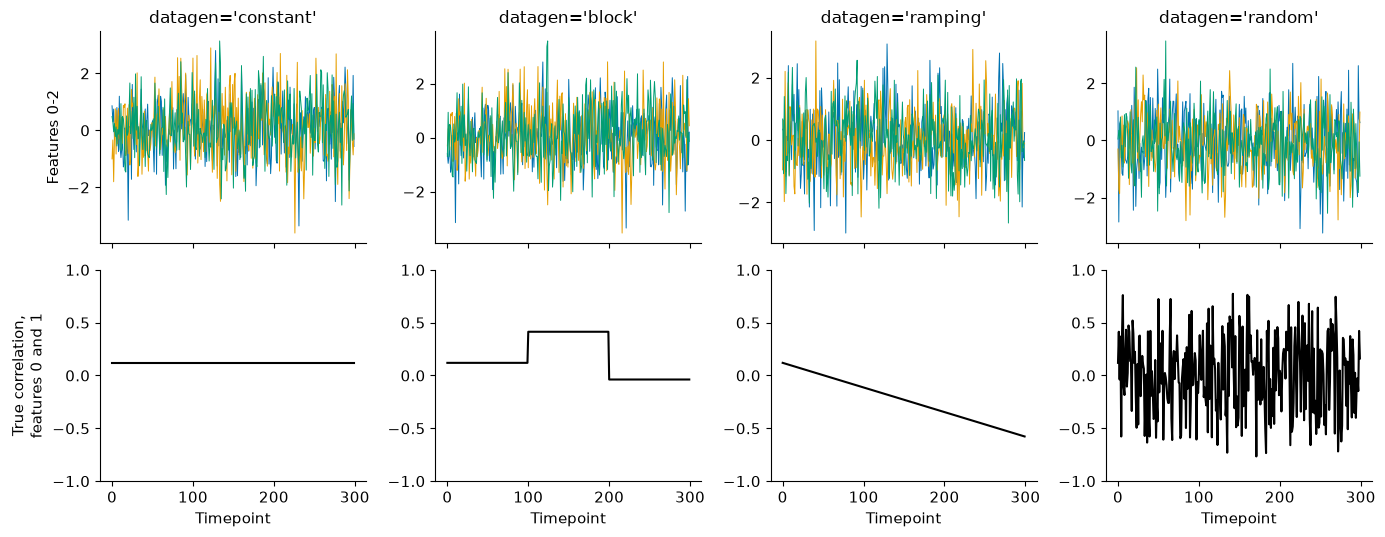

In [3]:
T, K = 300, 10
kinds = ['constant', 'block', 'ramping', 'random']
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True)
for col, kind in enumerate(kinds):
    data, corrs = tc.simulate_data(datagen=kind, T=T, K=K, B=3, return_corrs=True, set_random_seed=7)
    axes[0, col].plot(data[:, :3], lw=0.7)
    axes[0, col].set_title(f"datagen='{kind}'")
    axes[1, col].plot(tc.vec2mat(corrs)[0, 1], color='k', lw=1.5)
    axes[1, col].set(ylim=(-1, 1), xlabel='Timepoint')
axes[0, 0].set_ylabel('Features 0-2')
axes[1, 0].set_ylabel('True correlation,\nfeatures 0 and 1')
fig.tight_layout()
plt.show()

`S` gives a list of subjects that share the template. By default each subject's activity is its own draw; `subject_noise` makes them share one draw (see the [subjects tutorial](subjects.ipynb)).

## 2. Structure at a chosen order

`simulate_data(order=n)` puts a `p x p` template at order `n` only. The features form `p` blocks of `2**(n-1)` columns. Only the product of all of a block's columns (its **carrier**) follows the template, so the orders below `n` hold no structure. `tc.min_features` gives the number of features this needs.

In [4]:
for p in (3, 4):
    print(f'p = {p}: features needed at orders 1-5:', [tc.min_features(n, p=p) for n in range(1, 6)])

data2, truth2 = tc.simulate_data(datagen='block', K=8, T=600, B=4, order=2,
                                 return_corrs=True, set_random_seed=0)
print('truth keys:', sorted(truth2))
print('blocks (columns of each carrier):', truth2['blocks'].tolist())
print('template:', truth2['corrs'].shape)

p = 3: features needed at orders 1-5: [3, 6, 12, 24, 48]
p = 4: features needed at orders 1-5: [4, 8, 16, 32, 64]
truth keys: ['blocks', 'corrs', 'order', 'requested']
blocks (columns of each carrier): [[0, 1], [2, 3], [4, 5], [6, 7]]
template: (600, 10)


`tc.carrier_columns(blocks, level, K)` says where the carriers are in the unreduced output of each order: at level 1 they are the co-fluctuations of each block's pair of columns. The product of a block's two columns follows the template, while each column alone carries nothing.

In [5]:
level1 = tc.carrier_columns(truth2['blocks'], 1, 8)
print('carrier columns at level 1:', np.asarray(level1).ravel().tolist())

z = (data2 - data2.mean(0)) / data2.std(0)
carriers = np.column_stack([z[:, a] * z[:, b] for a, b in truth2['blocks']])
iu = np.triu_indices(4, 1)
true_mats = tc.vec2mat(truth2['corrs'])
true_c, carrier_c, column_c = [], [], []
for event in range(4):  # 4 events of 150 timepoints
    rows = slice(150 * event, 150 * (event + 1))
    true_c.append(true_mats[iu[0], iu[1], 150 * event])
    carrier_c.append(np.corrcoef(carriers[rows].T)[iu])
    column_c.append(np.corrcoef(data2[rows][:, truth2['blocks'][:, 0]].T)[iu])
true_c = np.concatenate(true_c)
print('match with the template (r over events and pairs):')
print('  products of each block\'s columns:', np.corrcoef(np.concatenate(carrier_c), true_c)[0, 1].round(2))
print('  first column of each block:      ', np.corrcoef(np.concatenate(column_c), true_c)[0, 1].round(2))

carrier columns at level 1: [8, 21, 30, 35]
match with the template (r over events and pairs):
  products of each block's columns: 0.97
  first column of each block:       0.09


`tc.simulate_multi_order` places several orders side by side in disjoint groups of features, each with its own template.

In [6]:
multi, truths = tc.simulate_multi_order([1, 2], p=4, T=400, set_random_seed=0)
print('data:', multi.shape)
for t in truths:
    print(f"order {t['order']}: columns {np.asarray(t['blocks']).ravel().tolist()}")

data: (400, 12)
order 1: columns [0, 1, 2, 3]
order 2: columns [4, 5, 6, 7, 8, 9, 10, 11]


`tc.nested_template` gives the order-2 truth implied by an order-1 template: the correlations among the co-fluctuations of Gaussian features. Below it is compared with the co-fluctuations of a long simulation with a constant template.

In [7]:
const, const_corrs = tc.simulate_data(datagen='constant', T=20000, K=4, return_corrs=True, set_random_seed=0)
cofluct = tc.timecorr(const, weights_function=tc.eye_weights, weights_params=tc.eye_params)
implied = tc.vec2mat(tc.nested_template(const_corrs[0]))
observed = np.corrcoef(cofluct.T)
iu2 = np.triu_indices(implied.shape[0], 1)
print('order-2 entries:', len(iu2[0]))
print('largest |observed - implied|:', np.abs(observed - implied)[iu2].max().round(3))

order-2 entries: 45
largest |observed - implied|: 0.029


## 3. `simulate_nested`: modules in supergroups

Nodes form modules, and modules form supergroups. Each supergroup has a slow strength `h` that sets how strongly the couplings of its modules move together, so `h` is a signal at order 2 (it lives in the correlations of the couplings). Each module's coupling `g` over time is in `truth['g']`.

2 subjects of (1000, 108) | modules: 18 | supergroups: 6


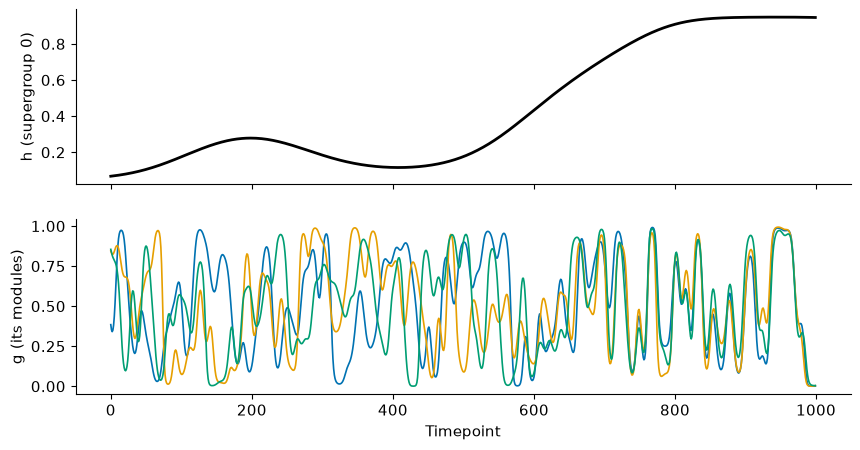

In [8]:
nested, ntruth = tc.simulate_nested(S=2, T=1000, set_random_seed=0)
print(len(nested), 'subjects of', nested[0].shape, '| modules:', ntruth['module'].max() + 1,
      '| supergroups:', ntruth['supergroup'].max() + 1)
modules = np.unique(ntruth['module'][ntruth['supergroup'] == 0])

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(ntruth['h'][:, 0], color='k', lw=2)
axes[0].set(ylabel='h (supergroup 0)')
axes[1].plot(ntruth['g'][0][:, modules], lw=1.2)
axes[1].set(xlabel='Timepoint', ylabel='g (its modules)')
plt.show()

## 4. `simulate_hierarchy`: groups of any depth

`simulate_hierarchy` nests groups to any depth: modules, groups of modules, and so on. Each group has a signal at its own time scale (`taus`, one per level) that sets how strongly its children are coupled. `truth['groups']` gives each node's group at every level.

data: (1000, 72) | groups per level: [18, 6, 2]


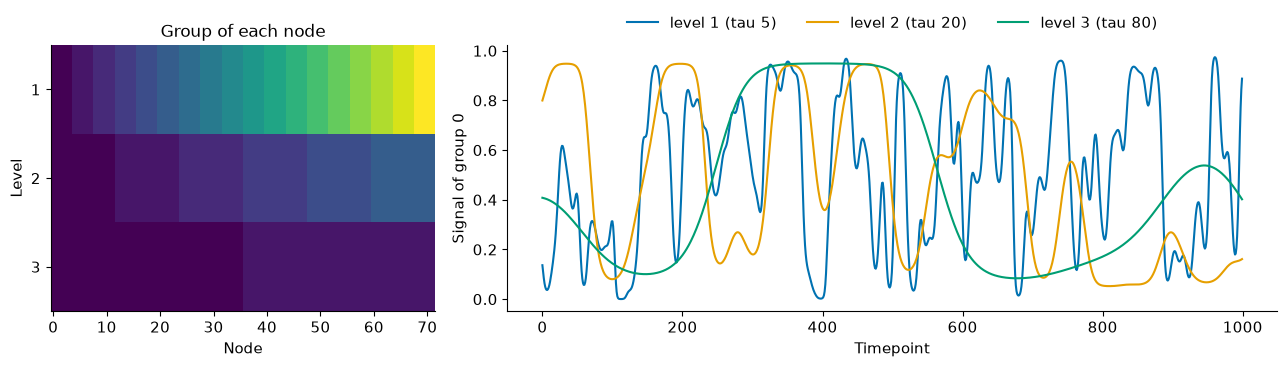

In [9]:
hier, htruth = tc.simulate_hierarchy(S=2, T=1000, nodes_per_module=4, branching=(3, 3), n_top=2,
                                     taus=(5, 20, 80), set_random_seed=0)
print('data:', hier[0].shape, '| groups per level:', [len(np.unique(g)) for g in htruth['groups']])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1, 2]})
axes[0].imshow(htruth['groups'], aspect='auto', cmap='viridis', interpolation='nearest')
axes[0].set(xlabel='Node', ylabel='Level', yticks=[0, 1, 2], yticklabels=[1, 2, 3],
            title='Group of each node')
for level, s in enumerate(htruth['signals'][0]):
    axes[1].plot(s[:, 0], lw=1.5, label=f'level {level + 1} (tau {htruth["taus"][level]})')
axes[1].set(xlabel='Timepoint', ylabel='Signal of group 0')
axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
plt.show()

The [higher-order tutorial](higher_order.ipynb) recovers these signals. Next: [higher orders](higher_order.ipynb).